Number of vertices: 34
Number of edges: 78


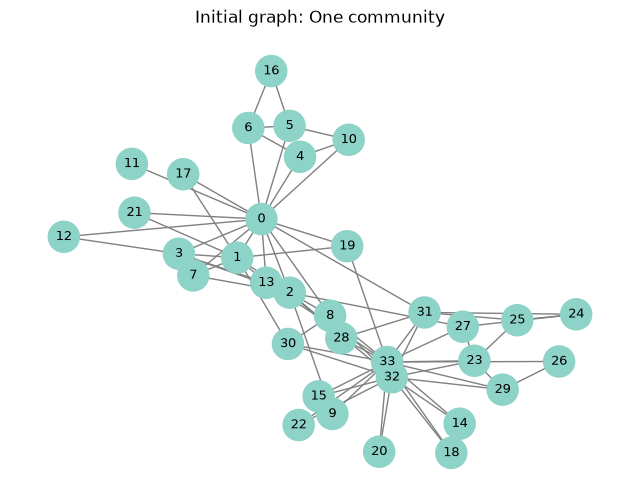

Communities: 2, Modularity: 0.4036


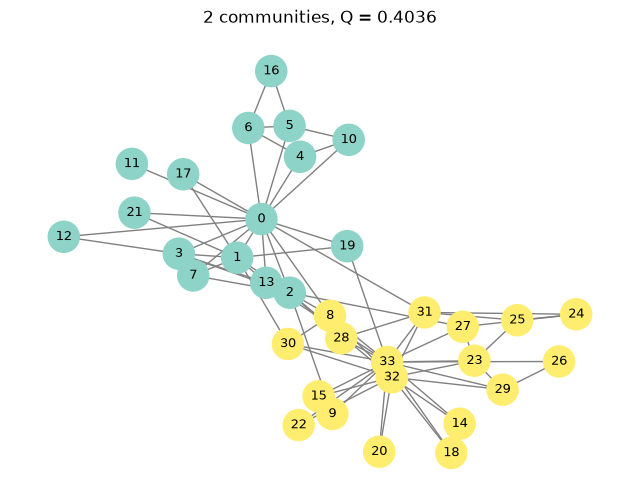

Communities: 3, Modularity: 0.4140


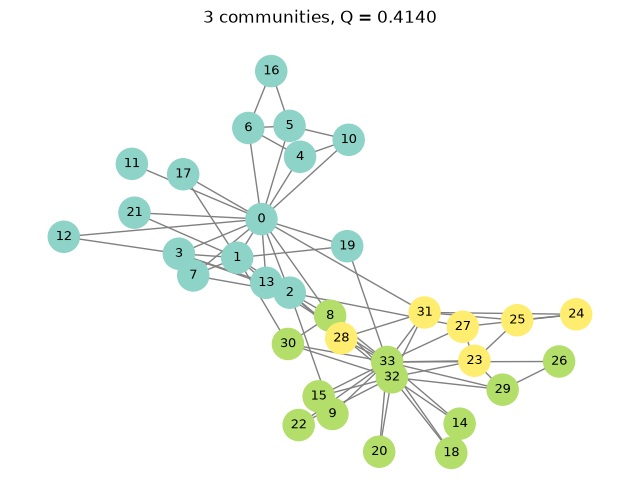

Communities: 4, Modularity: 0.4211


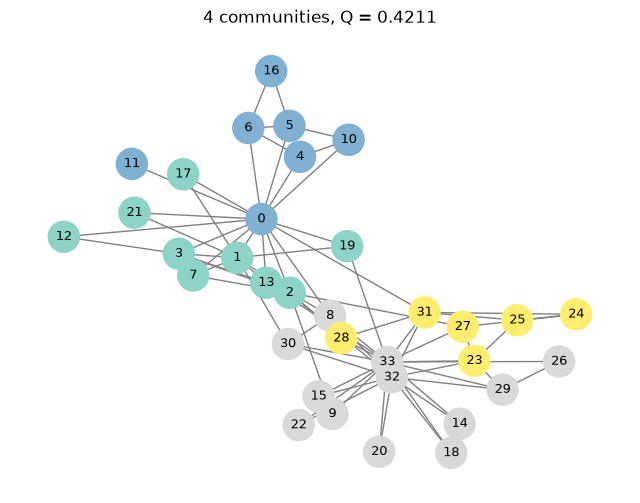


Final number of communities: 4
Final modularity: 0.4211
Community 1: [1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 2: [0, 4, 5, 6, 10, 11, 16]
Community 3: [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
Community 4: [23, 24, 25, 27, 28, 31]


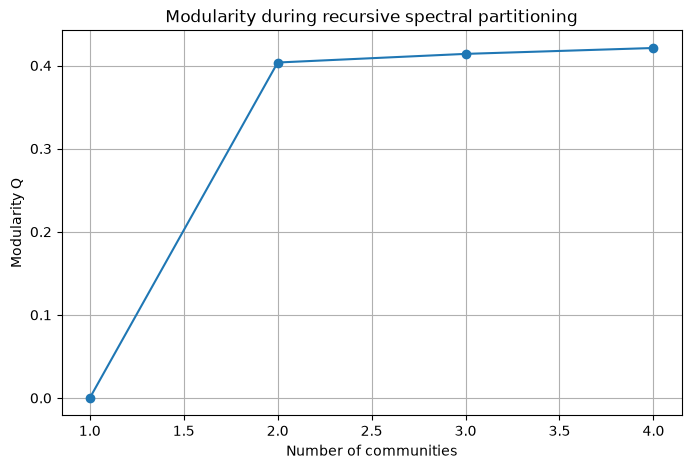


Network metrics:
Node | Degree | Betweenness | Closeness | Clustering
   0 |     16 |      0.4376 |    0.5690 |     0.1500
   1 |      9 |      0.0539 |    0.4853 |     0.3333
   2 |     10 |      0.1437 |    0.5593 |     0.2444
   3 |      6 |      0.0119 |    0.4648 |     0.6667
   4 |      3 |      0.0006 |    0.3793 |     0.6667
   5 |      4 |      0.0300 |    0.3837 |     0.5000
   6 |      4 |      0.0300 |    0.3837 |     0.5000
   7 |      4 |      0.0000 |    0.4400 |     1.0000
   8 |      5 |      0.0559 |    0.5156 |     0.5000
   9 |      2 |      0.0008 |    0.4342 |     0.0000
  10 |      3 |      0.0006 |    0.3793 |     0.6667
  11 |      1 |      0.0000 |    0.3667 |     0.0000
  12 |      2 |      0.0000 |    0.3708 |     1.0000
  13 |      5 |      0.0459 |    0.5156 |     0.6000
  14 |      2 |      0.0000 |    0.3708 |     1.0000
  15 |      2 |      0.0000 |    0.3708 |     1.0000
  16 |      2 |      0.0000 |    0.2845 |     1.0000
  17 |      2 |      0.0000 

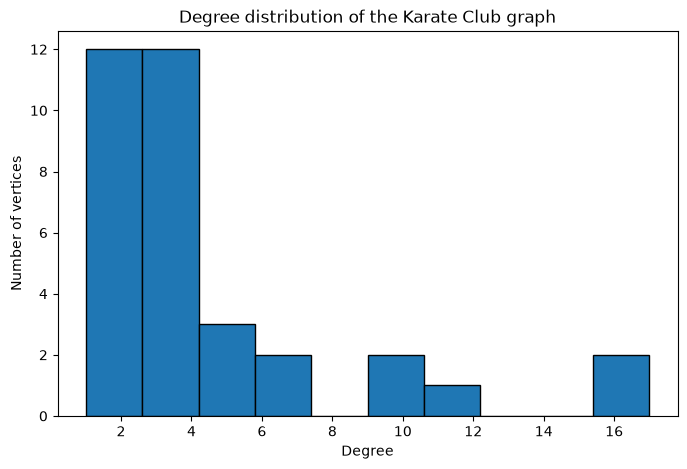

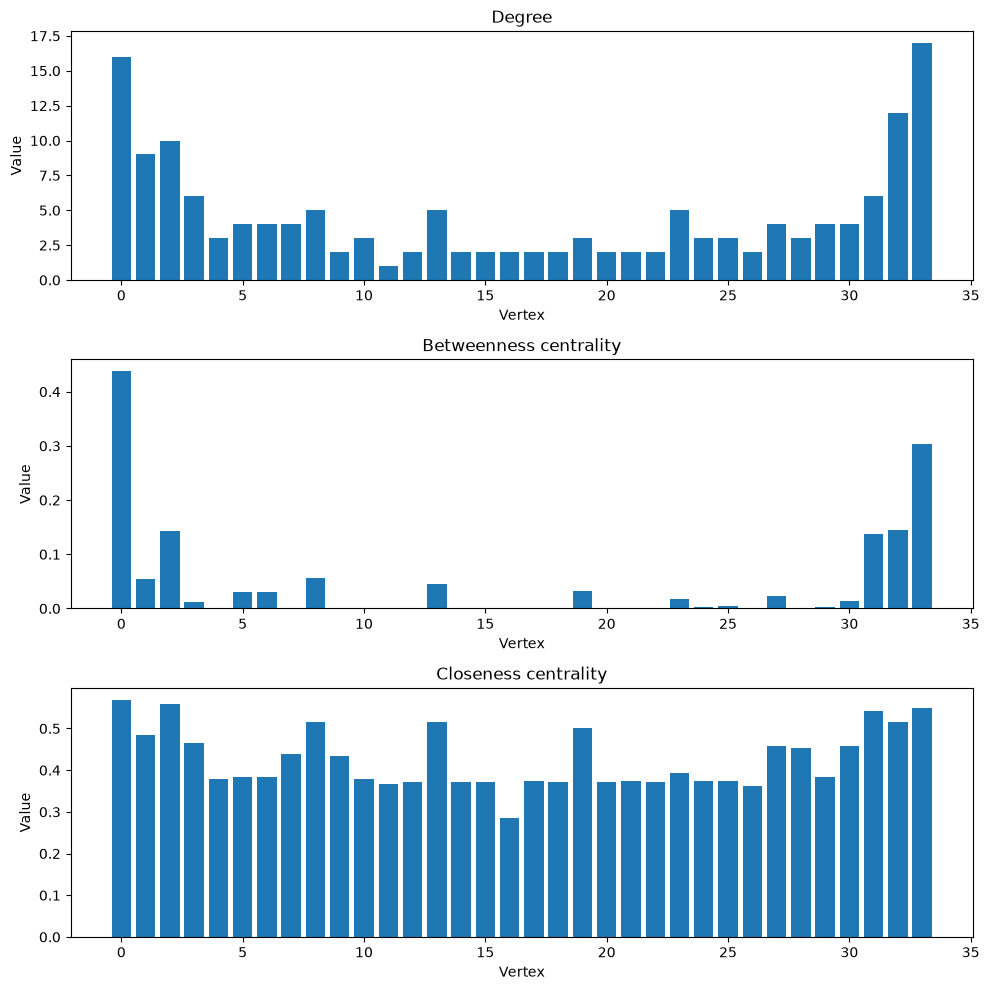

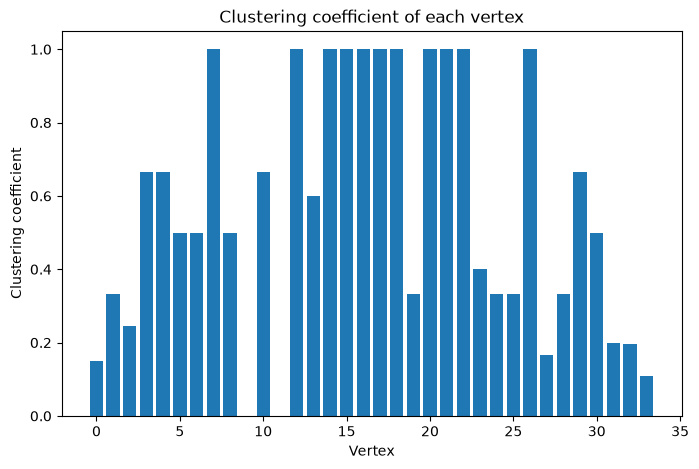

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Import the Karate Club graph
# --------------------------------------------------
G = nx.karate_club_graph()

print("Number of vertices:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

# Fixed layout for consistent visualizations
pos = nx.spring_layout(G, seed=42)

# Original club labels
clubs = nx.get_node_attributes(G, "club")

# --------------------------------------------------
# 2. Calculate modularity
# --------------------------------------------------
def calculate_modularity(G, communities):
    return nx.community.modularity(G, communities)


# --------------------------------------------------
# 3. Draw communities
# --------------------------------------------------
def draw_communities(G, communities, title):
    node_colors = {}
    for i, community in enumerate(communities):
        for node in community:
            node_colors[node] = i

    colors = [node_colors[node] for node in G.nodes()]

    plt.figure(figsize=(8, 6))
    nx.draw_networkx(
        G,
        pos,
        node_color=colors,
        cmap=plt.cm.Set3,
        with_labels=True,
        node_size=500,
        font_size=9,
        edge_color="gray"
    )
    plt.title(title)
    plt.axis("off")
    plt.show()


# --------------------------------------------------
# 4. Spectral modularity partitioning
# --------------------------------------------------
def spectral_split(G, community):
    nodes = list(community)
    subgraph = G.subgraph(nodes)

    # Adjacency matrix and degrees within this community
    A = nx.to_numpy_array(subgraph, nodelist=nodes)
    k = A.sum(axis=1)
    m = A.sum() / 2

    # Cannot split a community with no internal edges
    if m == 0 or len(nodes) < 2:
        return None

    # Modularity matrix for the community
    B = A - np.outer(k, k) / (2 * m)

    # Correct the diagonal for the spectral split
    B = B - np.diag(B.sum(axis=1))

    # Leading eigenvector
    eigenvalues, eigenvectors = np.linalg.eigh(B)
    leading_index = np.argmax(eigenvalues)
    leading_eigenvalue = eigenvalues[leading_index]

    if leading_eigenvalue <= 1e-10:
        return None

    leading_vector = eigenvectors[:, leading_index]

    group1 = {
        nodes[i] for i in range(len(nodes))
        if leading_vector[i] >= 0
    }
    group2 = set(nodes) - group1

    if not group1 or not group2:
        return None

    return [group1, group2]


# --------------------------------------------------
# 5. Recursively improve modularity
# --------------------------------------------------
communities = [set(G.nodes())]
modularity_history = [calculate_modularity(G, communities)]

draw_communities(G, communities, "Initial graph: One community")

while True:
    best_gain = 0
    best_index = None
    best_split = None
    current_modularity = calculate_modularity(G, communities)

    # Try splitting each existing community
    for i, community in enumerate(communities):
        split = spectral_split(G, community)

        if split is None:
            continue

        candidate = communities[:i] + split + communities[i + 1:]
        candidate_modularity = calculate_modularity(G, candidate)
        gain = candidate_modularity - current_modularity

        if gain > best_gain:
            best_gain = gain
            best_index = i
            best_split = split

    # Stop if no split improves modularity
    if best_split is None:
        break

    communities = (
        communities[:best_index]
        + best_split
        + communities[best_index + 1:]
    )

    modularity = calculate_modularity(G, communities)
    modularity_history.append(modularity)

    print(
        f"Communities: {len(communities)}, "
        f"Modularity: {modularity:.4f}"
    )

    draw_communities(
        G,
        communities,
        f"{len(communities)} communities, Q = {modularity:.4f}"
    )

# --------------------------------------------------
# 6. Final results
# --------------------------------------------------
print("\nFinal number of communities:", len(communities))
print("Final modularity:", round(modularity_history[-1], 4))

for i, community in enumerate(communities, start=1):
    print(f"Community {i}: {sorted(community)}")

# Plot modularity as the number of communities increases
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(modularity_history) + 1),
    modularity_history,
    marker="o"
)
plt.xlabel("Number of communities")
plt.ylabel("Modularity Q")
plt.title("Modularity during recursive spectral partitioning")
plt.grid(True)
plt.show()

# --------------------------------------------------
# 7. Network metrics
# --------------------------------------------------
degree = dict(G.degree())
betweenness = nx.betweenness_centrality(G)
closeness = nx.closeness_centrality(G)
clustering = nx.clustering(G)

print("\nNetwork metrics:")
print("Node | Degree | Betweenness | Closeness | Clustering")

for node in G.nodes():
    print(
        f"{node:4d} | "
        f"{degree[node]:6d} | "
        f"{betweenness[node]:11.4f} | "
        f"{closeness[node]:9.4f} | "
        f"{clustering[node]:10.4f}"
    )

# Plot degree distribution
plt.figure(figsize=(8, 5))
plt.hist(list(degree.values()), bins=10, edgecolor="black")
plt.xlabel("Degree")
plt.ylabel("Number of vertices")
plt.title("Degree distribution of the Karate Club graph")
plt.show()

# Plot centrality measures for each vertex
fig, axes = plt.subplots(3, 1, figsize=(10, 10))

metrics = [
    (degree, "Degree"),
    (betweenness, "Betweenness centrality"),
    (closeness, "Closeness centrality")
]

for ax, (metric, title) in zip(axes, metrics):
    ax.bar(list(metric.keys()), list(metric.values()))
    ax.set_title(title)
    ax.set_xlabel("Vertex")
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

# Clustering coefficient distribution
plt.figure(figsize=(8, 5))
plt.bar(list(clustering.keys()), list(clustering.values()))
plt.xlabel("Vertex")
plt.ylabel("Clustering coefficient")
plt.title("Clustering coefficient of each vertex")
plt.show()
